In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from nem_battery.load import INTERIM_DIR

df = pd.read_parquet(INTERIM_DIR / "price_demand_sa1.parquet")

df["hour"] = df["interval_start"].dt.hour
df["month"] = df["interval_start"].dt.month

print(df.shape)
df.head()

(525888, 8)


,region,settlement_date,total_demand_mw,rrp,period_type,interval_start,hour,month
0,SA1,2021-10-01 00:05:00,1376.74,17.22,TRADE,2021-10-01 00:00:00,0,10
1,SA1,2021-10-01 00:10:00,1338.87,16.97,TRADE,2021-10-01 00:05:00,0,10
2,SA1,2021-10-01 00:15:00,1323.73,8.57,TRADE,2021-10-01 00:10:00,0,10
3,SA1,2021-10-01 00:20:00,1336.61,8.40,TRADE,2021-10-01 00:15:00,0,10
4,SA1,2021-10-01 00:25:00,1326.17,8.49,TRADE,2021-10-01 00:20:00,0,10


In [ ]:
df["hour"] = df["interval_start"].dt.hour
df["month"] = df["interval_start"].dt.month

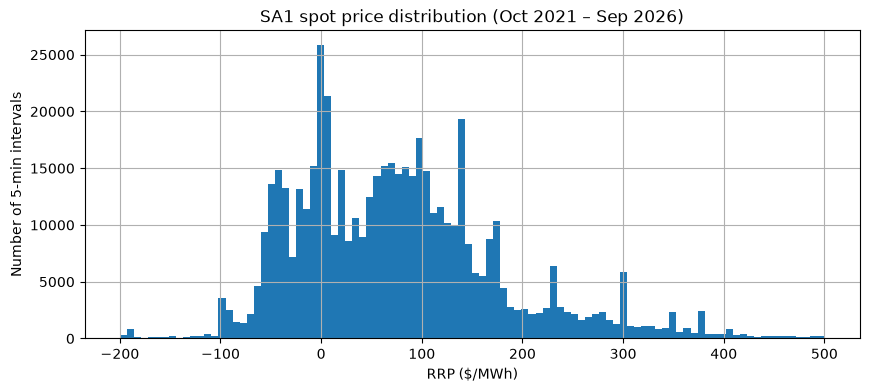

Shown: 98.7% of intervals. Outside -200 to 500: 6,945


In [4]:
low, high = -200, 500
inside = df["rrp"].between(low, high)

df.loc[inside, "rrp"].hist(bins=100, figsize=(10, 4))
plt.title("SA1 spot price distribution (Oct 2021 - Sep 2026)")
plt.xlabel("RRP ($/MWh)")
plt.ylabel("Number of 5-min intervals")
plt.show()

print(f"Shown: {inside.mean():.1%} of intervals. Outside {low} to {high}: {(~inside).sum():,}")

- At 0: the tallest bar around 5,477 exact-zero intevals plus near-zero prices pilling up 
- The sharp spikes at specific prices around 0,140, 230, 300 arent random. A plausible explanation is that generator offer electricity in price bands at chosen round numbers, and when one of those offers sets the price, many intervals land on the same value. $300 is also a well-known level in Australia electricity hedging contracts.
- The right tails is up to 500.

#### Price per hour of day

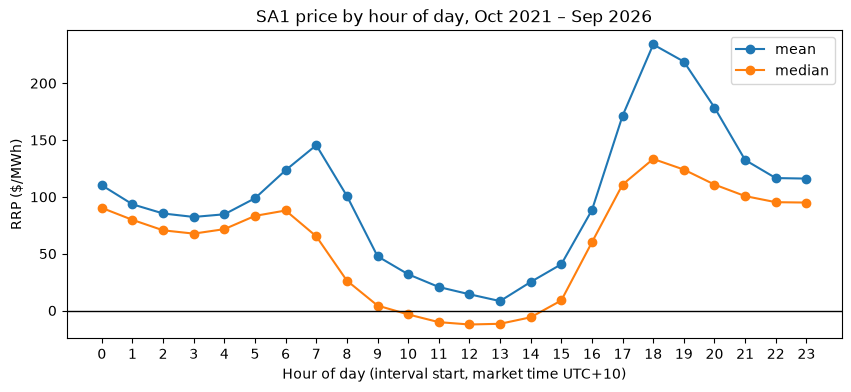

       mean  median
hour               
0     110.2    90.3
1      93.4    79.8
2      85.4    70.6
3      82.3    67.7
4      84.7    71.6
5      98.8    83.3
6     123.4    88.0
7     145.5    65.3
8     100.8    26.3
9      47.7     4.4
10     31.9    -3.4
11     20.7   -10.2
12     14.3   -12.3
13      8.3   -11.7
14     25.1    -6.0
15     40.7     8.9
16     88.4    60.1
17    171.4   110.8
18    234.0   133.3
19    219.0   124.0
20    178.6   110.8
21    132.4   100.7
22    116.5    95.3
23    116.1    95.0


In [7]:
hourly = df.groupby("hour")["rrp"].agg(["mean", "median"])

fig, ax = plt.subplots(figsize=(10, 4))
hourly.plot(ax=ax, marker="o")
ax.axhline(0, color="black", linewidth=1)
ax.set_title("SA1 price by hour of day, Oct 2021 – Sep 2026")
ax.set_xlabel("Hour of day (interval start, market time UTC+10)")
ax.set_ylabel("RRP ($/MWh)")
ax.set_xticks(range(24))
plt.show()

print(hourly.round(1))

The most expensive price is around 18PM and the lowest one around 9AM to 15PM. 

#### When are negative prices most common?

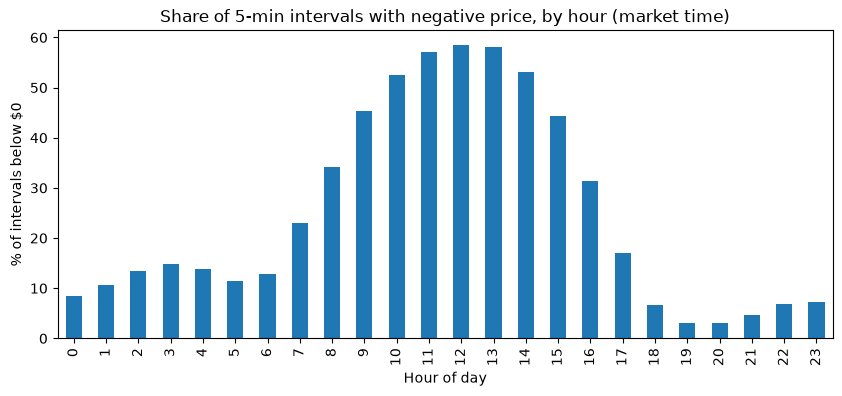

hour
0      8.5
1     10.7
2     13.3
3     14.8
4     13.9
5     11.4
6     12.8
7     23.1
8     34.3
9     45.3
10    52.5
11    57.1
12    58.5
13    58.0
14    53.2
15    44.4
16    31.4
17    17.0
18     6.6
19     3.1
20     3.1
21     4.7
22     6.9
23     7.2
Name: rrp, dtype: float64


In [9]:
neg_share = (df["rrp"] < 0).groupby(df["hour"]).mean() * 100

fig, ax = plt.subplots(figsize=(10, 4))
neg_share.plot(kind="bar", ax=ax)
ax.set_title("Share of 5-min intervals with negative price, by hour (market time)")
ax.set_xlabel("Hour of day")
ax.set_ylabel("% of intervals below $0")
plt.show()

print(neg_share.round(1))


More than half of all midday intervals are negative, peaking at about 58% at 12-13h. Around 19-20h, almost never negative but the negative prices also occur at night, with no solar. Assumption for the negative prices at night because of the battery.

#### Is the oppurtunity the same all year?

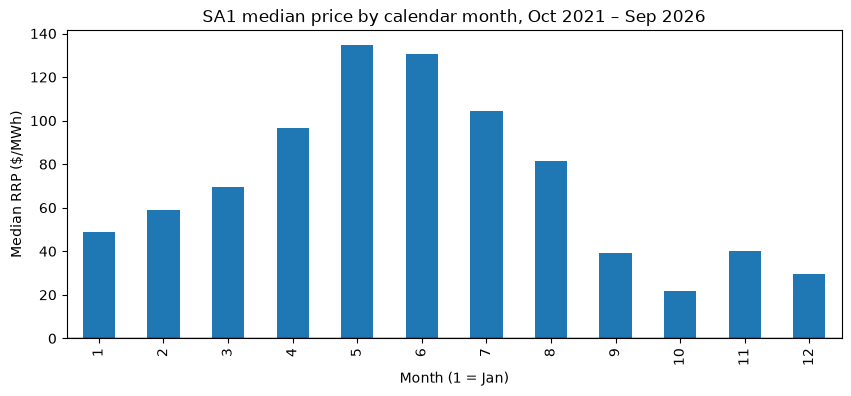

month
1      48.8
2      58.8
3      69.8
4      96.5
5     134.7
6     130.4
7     104.4
8      81.4
9      39.0
10     21.6
11     40.0
12     29.4
Name: rrp, dtype: float64


In [11]:
monthly = df.groupby("month")["rrp"].median()

fig, ax = plt.subplots(figsize=(10, 4))
monthly.plot(kind="bar", ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("SA1 median price by calendar month, Oct 2021 – Sep 2026")
ax.set_xlabel("Month (1 = Jan)")
ax.set_ylabel("Median RRP ($/MWh)")
plt.show()

print(monthly.round(1))

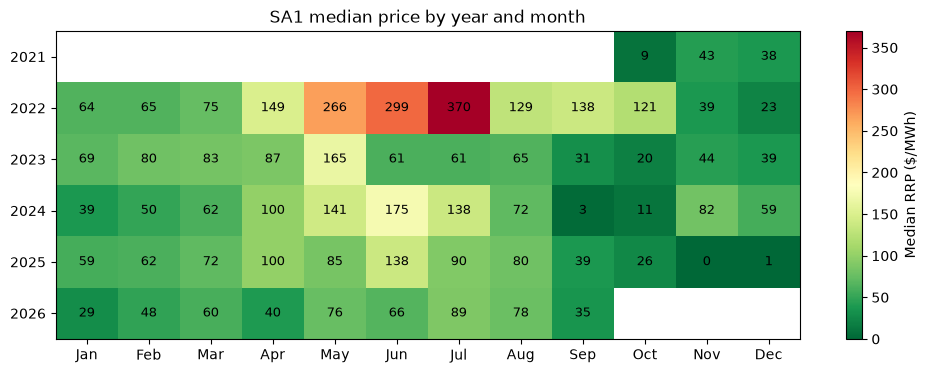

In [15]:

by_year_month = df.pivot_table(
    index=df["interval_start"].dt.year,
    columns="month",
    values="rrp",
    aggfunc="median",
).round(0)

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(by_year_month.values, cmap="RdYlGn_r", aspect="auto")

ax.set_xticks(range(12))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(len(by_year_month.index)))
ax.set_yticklabels(by_year_month.index)

for i in range(by_year_month.shape[0]):
    for j in range(by_year_month.shape[1]):
        value = by_year_month.iloc[i, j]
        if not np.isnan(value):
            ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=9)

fig.colorbar(im, ax=ax, label="Median RRP ($/MWh)")
ax.set_title("SA1 median price by year and month")

plt.show()

The heatmap shows the high winter prices, peaking around May to Jul, most driven by the 2022 energy crisis. Seasonality was real but much smaller, and spring prices fell towards zero over time. 

### Summary of findings

**1. Data**

The dataset period is from Oct 2021 to Sep 2026, all under 5-min intervals, period ending, market time UTC +10, and no daylight saving. 

**2. Data quality** 

The dataset includes 525,888 rows (1,826 days x 288), no duplicates and missing intervals.

**3. Price (RRP)**

The median and mean of the price are $67.58 and $98.74, so right-skewed, spikes pull the mean up. Negative price is around 24.7% at or below $0 with the market floor is around -$1000 on 13 Oct 2021, 08:45 and maximum is $20,300 on 18 Jan 2026, 19:30. 

**4. Demand**

The median is 1,354 MW, maximum 3,327 MW on 12 Feb 2025, 18:55 with the price $14,500 (summer evening) and minimum is -311 MW on Christmas Day 2025, 13:35 at the price -$300

**5. Time-of-day pattern**

10-14h the negative price share is around 52-58%, peaking about 58% at 12-13h, 19-20h is just around 3% and 0-6h is still having negatives, possibly wind (assumption)
    
**6. Seasonality and trend**

Spring (Sep-Dec) is consistently cheapest, winter is moderately higher most years